# LUMA - Lokalny Urok Mistrzostwa Artystycznego

LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [2]:
RNG_SEED = 20261020
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261020


### Zdefiniowanie "stałych"

In [3]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

#### "Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [4]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # średni popyt lokalny 
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # popyt turystyczny
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135], # średnia cena jednostkowa
})

#### Wyliczony "typowy" przychód tygodniowy: (lokalni + turyści) * cena

In [5]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [6]:
catalog

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

##### Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywmym) i opcjonalnymi boostami (%)

In [7]:
def determine_demand(catalog, rng, variance = 0.15, boost_loc = 0.0, boost_tur = 0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()

    eps_loc = np.clip(rng.normal(loc=1.0, scale = variance, size = len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale = variance, size = len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)

    return df[["category", "demand_loc", "demand_tur"]]

##### Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [8]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on = "category", how = "left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "demand_loc", "demand_tur", "revenue_loc", "revenue_tur", "revenue_pln"]]

##### Generowanie danych tygodniowych

In [9]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc = 0.0, boost_tur = 0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych

In [10]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychów w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,demand_loc,demand_tur,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,86,49,688,392,1080,8
1,Tekstylia,177,28,21240,3360,24600,120
2,Biżuteria,89,78,13350,11700,25050,150
3,Rękodzieło,98,28,22540,6440,28980,230
4,Przetwory,193,92,7720,3680,11400,40
5,Dekoracje,140,32,4900,1120,6020,35
6,Stolarka,76,57,19000,14250,33250,250
7,Masarstwo,85,41,18275,8815,27090,215
8,Alkohole,138,76,18630,10260,28890,135


Łączny przychów w tygodniu 1 (PLN):  186360


## Analiza i wizualizacja danych

##### Podstawowe wykresy

<Axes: >

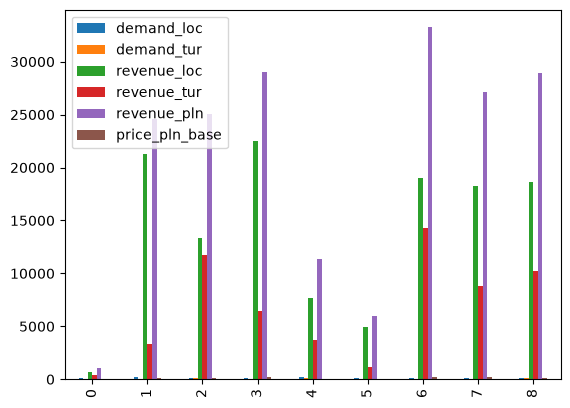

In [11]:
t1.plot.bar()

<Axes: >

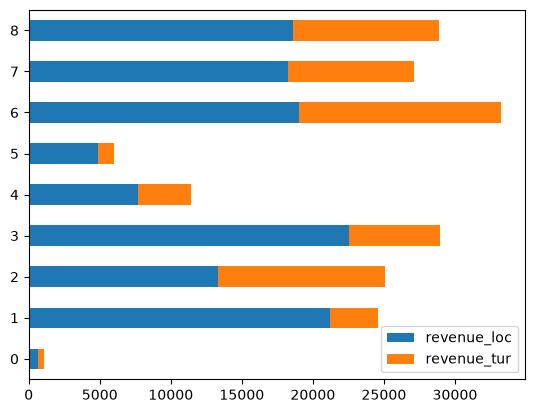

In [12]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

##### Minimalny wykres

<BarContainer object of 9 artists>

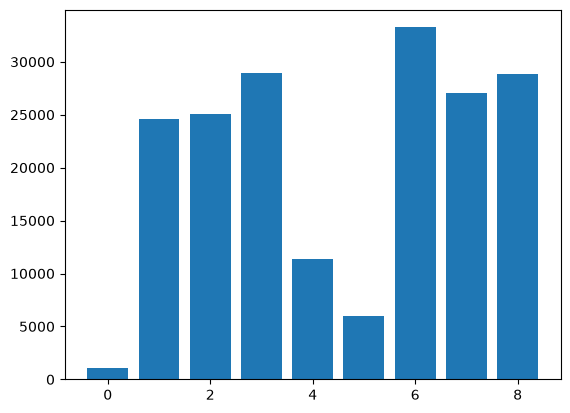

In [13]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

##### Jawne tworzenie i wyświetlanie wykresu

In [14]:
heights = t1["revenue_pln"]
categories = t1["category"]

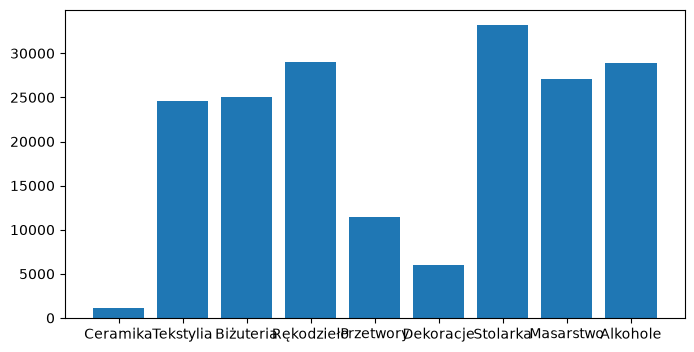

In [15]:
plt.figure(figsize=(8,4))
plt.bar(categories, heights)
plt.show()

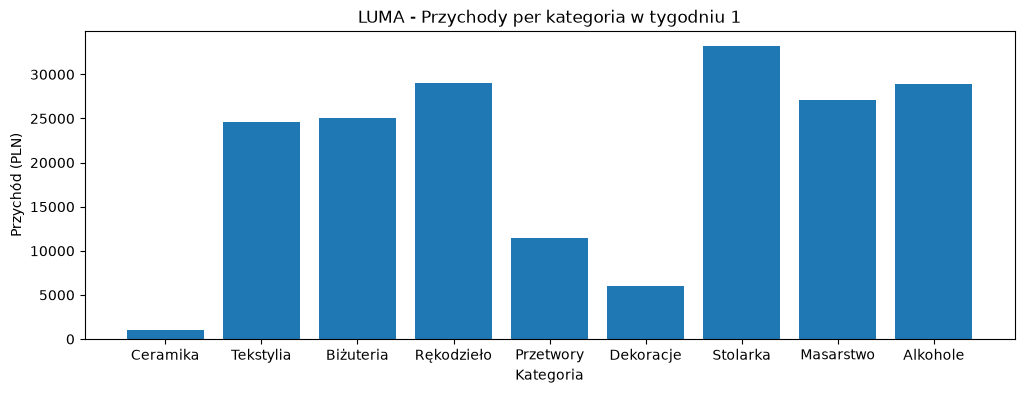

In [16]:
plt.figure(figsize=(12,4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

#### Etykiety wartości i formatowanie liczb

In [24]:
def format_pln(x: float) -> str:
    return f"{int(round(x)):,} zł".replace(",", "\u202f")

In [30]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim()
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad)

In [31]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha="center", va="bottom")

In [44]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000.0
    if decimals == 0:
        s = f"{int(round(v))}".replace(",", '\u202f')
    else: 
        s = f"{v:.{decimals}f}".replace(",", '\u202f').replace(".", ",")
    return s + " tys."

In [45]:
print(format_tys(123456.678))

123 tys.


In [46]:
def format_mln(x: float, decimals: int = 0) -> str:
    v = x / 1000000.0
    if decimals == 0:
        s = f"{int(round(v))}".replace(",", '\u202f')
    else: 
        s = f"{v:.{decimals}f}".replace(",", '\u202f').replace(".", ",")
    return s + " mln"

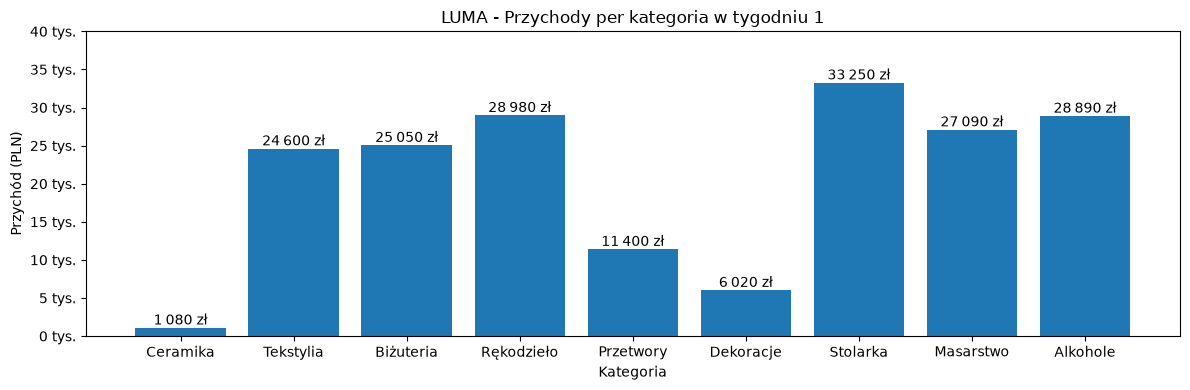

In [48]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
ypos, ylab_old = plt.yticks()
ylab_new = [format_tys(y) for y in ypos]
plt.yticks(ypos, ylab_new)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [49]:
def format_yticks_tys():
    ypos, _ = plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

#### Sortowanie kategorii dla łatwiejszego porównania

In [52]:
t1_sorted = t1.sort_values("revenue_pln", ascending=False).reset_index()
categories = t1_sorted["category"]
heights = t1_sorted["revenue_pln"]


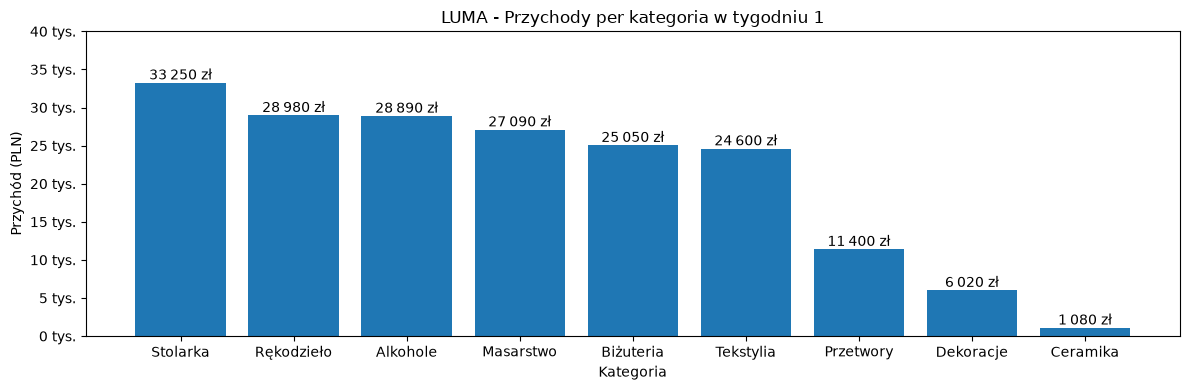

In [53]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_yticks_tys()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

#### Siatka w tle wykresu

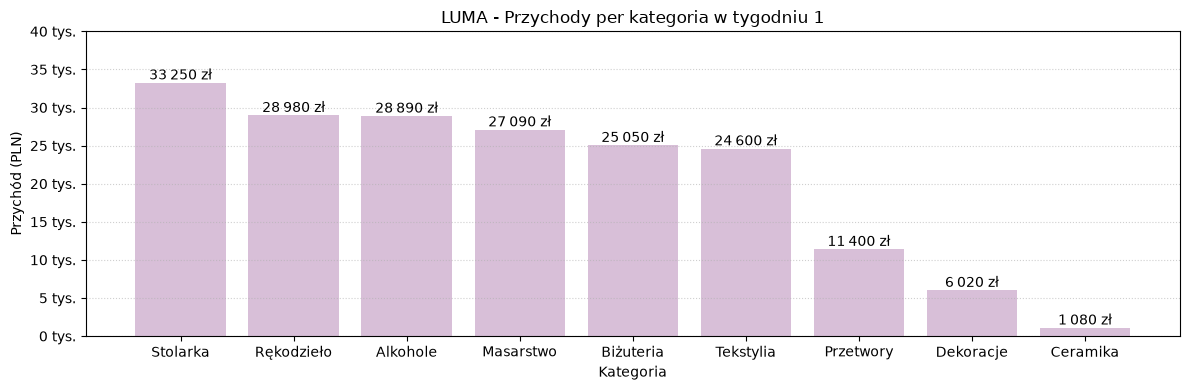

In [58]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights, color="thistle")
pad_axis()
label_bars_pln(bars)
format_yticks_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()